# Baseline Model
#### Loading the data

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
    
from src.data import build_index, make_split, check_split, split_dataframe, set_seed
from src.dataset import GTSRBDataset

df = build_index(PROJECT_ROOT/'data'/'Train')
df = make_split(df, 5, 42)
check_split(df)

Number of paths: 39209
Number of Tracks: 1307
Number of classes: 43
train: 43/43 classes
val: 43/43 classes

Leak check:
No leaked tracks.

5 least common classes in Validation set:
split  train  val
label            
0          6    1
19         6    1
29         8    1
32         7    1
37         6    1


In [2]:
import torchvision.transforms as transforms

base_transforms = transforms.Compose([
    transforms.Resize((32,32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
])

In [3]:
from PIL import Image

img = Image.open(PROJECT_ROOT/'data'/'Train'/'7'/'00007_00002_00028.png').convert("RGB")
t_image = base_transforms(img)
print(t_image.shape)
print(t_image.dtype)
print(t_image.min())
print(t_image.max())

torch.Size([3, 32, 32])
torch.float32
tensor(-0.7333)
tensor(1.)


In [4]:
Tdf, Vdf = split_dataframe(df)
train_ds = GTSRBDataset(df=Tdf, transform=base_transforms)
val_ds = GTSRBDataset(df=Vdf, transform=base_transforms)

In [5]:
from torch.utils.data import DataLoader
batch_size = 64
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)

#Testing
imgs, labels = next(iter(train_loader))
print(f"Batch shape: {imgs.shape}")
print(f"#Labels: {labels.shape}     Type: {labels.dtype}")

Batch shape: torch.Size([64, 3, 32, 32])
#Labels: torch.Size([64])     Type: torch.int64


#### Model and Training Loop

In [6]:
import torch.nn as nn

class BaseLine_Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3,16,3, padding=1)
        self.conv2 = nn.Conv2d(16,32,3, padding=1)
        self.conv3 = nn.Conv2d(32,64,3,padding=1)
        self.linear = nn.Linear(1024,43)
        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(self.pool(self.relu(self.conv3(x))))
        x = self.linear(x)
        return x

In [7]:
import torch
set_seed()
model = BaseLine_Model()
output = model(torch.zeros(5,3,32,32))
print(f"Shape: {output.shape}")

Shape: torch.Size([5, 43])


In [8]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)
if torch.cuda.is_available(): device='cuda'
else: device='cpu'
print(f"Device: {device}")

Device: cuda


In [10]:
epochs = 20
train_history = []
val_history = []
train_acc_history = []
val_acc_history = []
model.to(device)
for i in range(1, epochs+1):
    avg_loss = 0
    accuracy = 0
    model.train()
    for batch, label in train_loader:
        batch = batch.to(device)
        label = label.to(device)
        y_pred = model(batch)
        pred = y_pred.argmax(dim=1)
        accuracy += (pred == label).sum().item()
        loss = loss_fn(y_pred, label)
        avg_loss += loss.item() * batch.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    avg_loss = avg_loss/(len(train_ds))
    accuracy = accuracy/(len(train_ds))

    model.eval()
    with torch.inference_mode():
        loss_val = 0
        val_accuracy = 0
        for batch_val, label_val in val_loader:
            batch_val = batch_val.to(device)
            label_val = label_val.to(device)
            val_y_pred = model(batch_val)
            val_pred = val_y_pred.argmax(dim=1)
            val_accuracy += (val_pred == label_val).sum().item()
            loss_val += loss_fn(val_y_pred, label_val).item() * batch_val.size(0)
        loss_val = loss_val/(len(val_ds))
        val_accuracy = val_accuracy/(len(val_ds))
        train_history.append(avg_loss)
        val_history.append(loss_val)
        train_acc_history.append(accuracy)
        val_acc_history.append(val_accuracy)
        
        if i%5 == 0 or i == epochs or i == 1:
            print(f"Epoch: {i}")
            print(f"Training cost: {train_history[i-1]}   Validation cost: {val_history[i-1]}")
            print(f"Training accuracy: {round(train_acc_history[i-1]*100,2)}%   Validation accuracy: {round(val_acc_history[i-1]*100,2)}%")
            print()

Epoch: 1
Training cost: 0.4131639447114187   Validation cost: 0.8146097324291565
Training accuracy: 87.51%   Validation accuracy: 79.95%

Epoch: 5
Training cost: 0.05225561881510564   Validation cost: 0.800902610116403
Training accuracy: 98.5%   Validation accuracy: 87.2%

Epoch: 10
Training cost: 0.016801324395492638   Validation cost: 0.7650131554631678
Training accuracy: 99.49%   Validation accuracy: 89.17%

Epoch: 15
Training cost: 0.020525928471334744   Validation cost: 0.713431078951377
Training accuracy: 99.37%   Validation accuracy: 90.01%

Epoch: 20
Training cost: 0.009825484953907187   Validation cost: 0.666625462950715
Training accuracy: 99.73%   Validation accuracy: 91.54%



#### Evaluation

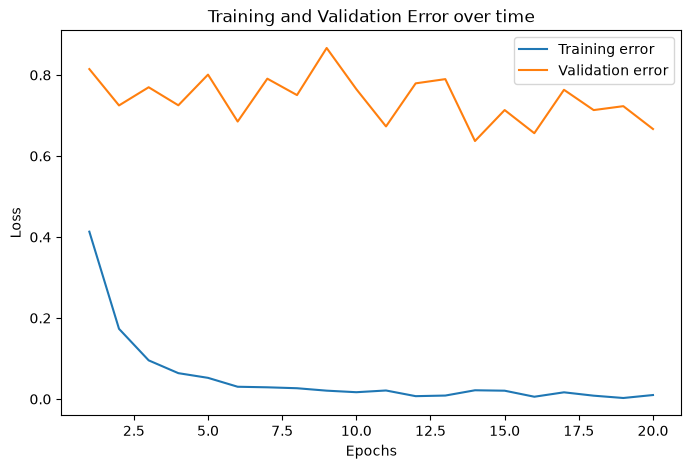

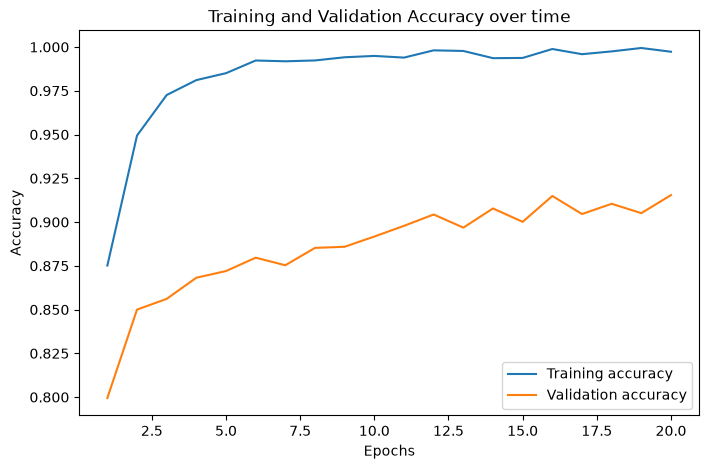

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1,len(train_history)+1), train_history, label='Training error')
plt.plot(range(1,len(val_history)+1), val_history, label='Validation error')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Error over time')
plt.legend()
plt.figure(figsize=(8, 5))
plt.plot(range(1,len(train_acc_history)+1), train_acc_history, label='Training accuracy')
plt.plot(range(1,len(val_acc_history)+1), val_acc_history, label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy over time')
plt.legend()
plt.show()

In [27]:
from sklearn.metrics import classification_report
import pandas as pd

model.eval()
all_preds, all_labels = [], []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(device)
        logits = model(images)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_labels.append(labels)
    y_preds = torch.cat(all_preds).numpy()
    y_labels = torch.cat(all_labels).numpy()

report = classification_report(y_labels, y_preds, zero_division=0, digits=3, output_dict=True)
pd.DataFrame(report).transpose().round(3)

,precision,recall,f1-score,support
0,0.882,0.500,0.638,30.000
1,0.934,0.880,0.906,450.000
2,0.904,0.918,0.911,450.000
3,0.915,0.996,0.954,270.000
4,0.915,0.995,0.953,390.000
5,0.907,0.869,0.888,360.000
6,1.000,0.933,0.966,90.000
7,0.980,0.990,0.985,300.000
8,0.949,0.963,0.956,270.000
9,0.932,0.967,0.949,300.000


In [29]:
print("Weakest classes:")
pd.DataFrame(report).T.round(3).sort_values(by="f1-score")

Weakest classes:


,precision,recall,f1-score,support
23,0.652,0.250,0.361,120.000
21,0.756,0.344,0.473,90.000
20,0.500,0.817,0.620,60.000
0,0.882,0.500,0.638,30.000
40,0.821,0.533,0.646,60.000
37,0.938,0.500,0.652,30.000
30,0.754,0.578,0.654,90.000
24,0.902,0.617,0.733,60.000
31,0.725,0.740,0.733,150.000
27,0.896,0.717,0.796,60.000


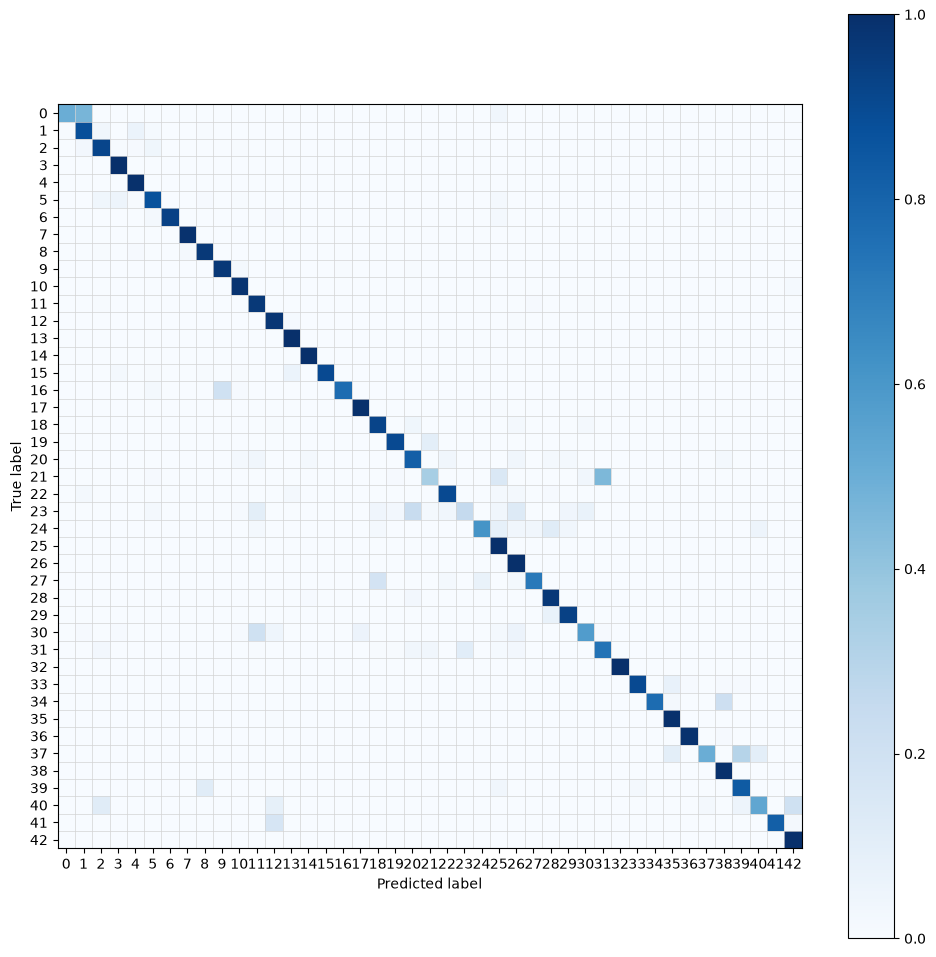

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

cm = confusion_matrix(y_labels, y_preds, labels=list(range(43)))

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(
    y_labels, y_preds,
    labels=list(range(43)),
    normalize="true",
    include_values=False,
    cmap="Blues",
    ax=ax,
)

ax.set_xticks(np.arange(-0.5, 43, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 43, 1), minor=True)
ax.grid(which="minor", color="lightgray", linewidth=0.5)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
plt.show()

#### Conclusions

##### Experimental Setup
* **Learning Rate:** 0.001
* **Parameters:** 67,659
* **Optimizer:** Adam
* **Batch Size:** 64
* **Epochs:** 20
* **Random Seed:** 42

##### Results
* **Validation Accuracy:** 91.5%
* **Macro F1-Score:** 86.0%
* **Training Loss:** 0.0098
* **Validation Loss:** 0.6666

---

##### Strengths
* **Rapid Initial Convergence:** As observed in the loss curves, the model converges rapidly during early training, achieving an 80% validation accuracy within the first epoch. 
* **Diminishing Returns with Extended Training:** By epoch 10, the validation curve begins to plateau, indicating that simply increasing the number of epochs will yield minimal improvement.
* **Solid Overall Performance:** A macro F1-score of 86% demonstrates strong general classification capability across most labels, suggesting that misclassifications are concentrated within a few specific classes.

##### Weaknesses
* **Fine-Grained Classification Errors:** While the vast majority of classes achieve an F1-score above 80%, a subset of visually similar traffic signs scores significantly lower:
  * **Classes 20, 21, 23, 27, 30, 31:** Triangular warning signs with red borders and distinct interior symbols.
  * **Classes 37, 40:** Blue circular mandatory signs containing directional arrows.
  * **Classes 0, 1:** Speed limit signs sharing identical outer circular profiles.
  
  This indicates that while the model successfully learns high-level features (such as color profiles and geometric silhouettes), it struggles to differentiate fine-grained interior symbols. Potential solutions include targeted **data augmentation** and/or **increasing input image resolution**.

* **Overfitting:** The loss trajectories reveal evident overfitting—training loss continues to decline toward near-zero while validation loss plateaus around 0.6-0.8. The model is memorizing training samples rather than generalizing well to unseen data. To resolve this, future iterations should incorporate **regularization techniques** (such as dropout, weight decay, or early stopping).